In [1]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import scipy

datapath = "../week3/collected_data_unlimited.csv"

df = pd.read_csv(datapath)
df['Timestamp'] = pd.to_datetime(df['Timestamp'])

df.head()

,Timestamp,Type,Name,CPU,Memory,Count
0,2024-03-01 11:09:35,Node,test-control-plane,827m,1300Mi,1
1,2024-03-01 11:09:35,Pod,test-app-79645bbddb-bxsjl,251m,24Mi,3
2,2024-03-01 11:09:35,Pod,test-app-79645bbddb-dct5l,250m,24Mi,3
3,2024-03-01 11:09:35,Pod,test-app-79645bbddb-qml4v,145m,21Mi,3
4,2024-03-01 11:10:35,Node,test-control-plane,510m,1357Mi,1


In [2]:
MAX_REPLICA_COUNT = df['Count'].max() + 1

replica_graphs = []

def get_replica_row(replica_num, group):
    if len(group) >= replica_num:
        return group.iloc[replica_num-1:replica_num]

grouped = df.groupby('Timestamp')

node_stats = grouped.apply(lambda x: x.iloc[0]).reset_index(drop=True)
pod_stats = grouped.apply(lambda x: x.iloc[1]).reset_index(drop=True)

node_stats['Memory'] = node_stats['Memory'].str.split("Mi").apply(lambda x: int(x[0]))

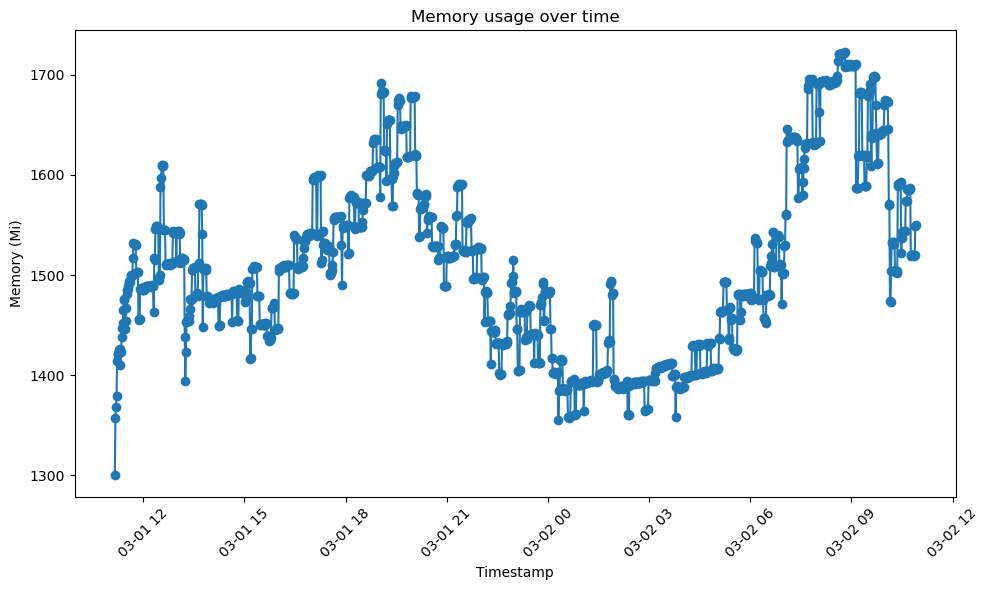

In [3]:
plt.figure(figsize=(10, 6))
plt.plot(node_stats.sort_values(by='Timestamp')['Timestamp'], node_stats['Memory'], marker='o', linestyle='-')
plt.title('Memory usage over time')
plt.xlabel('Timestamp')
plt.ylabel('Memory (Mi)')
plt.xticks(rotation=45)  
plt.tight_layout()  
plt.show()

In [4]:
#split data
time_to_split = node_stats['Timestamp'][700]
print(time_to_split)

2024-03-01 22:52:30


In [5]:
def get_timestamp(date):
    return date.timestamp()

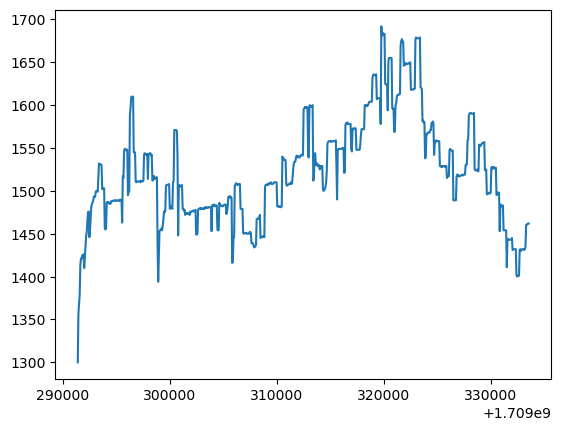

In [10]:
node_stats['Time'] = node_stats['Timestamp'].map(get_timestamp)
X = node_stats['Time'].to_numpy()
Y = node_stats['Memory'].to_numpy()

train_df = node_stats[node_stats['Timestamp'] <= time_to_split].copy()
train_df['Time'] = train_df['Timestamp'].map(get_timestamp)
X_train = train_df['Time'].to_numpy()
Y_train = train_df['Memory'].to_numpy()

plt.plot(X_train, Y_train)

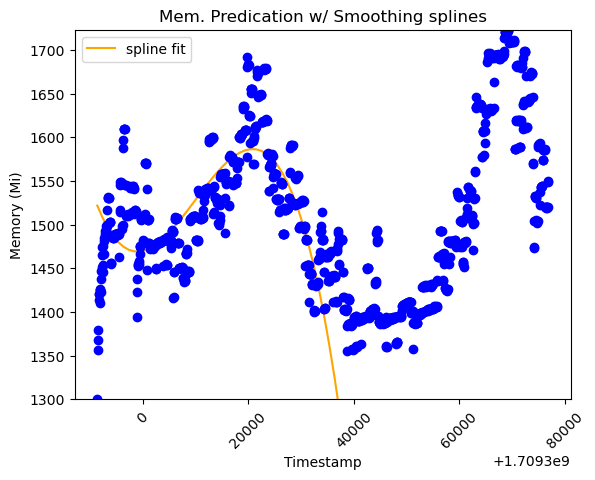

In [61]:
import sklearn
from scipy.interpolate import splrep, BSpline
#fit smoothing spline
tck_s = splrep(X_train, Y_train, s=(1000 * len(X)))

xnew = np.arange(np.min(X), np.max(X), 1000)
#plt.plot(X, Y, '-.', label='data')
#plt.plot(xnew, BSpline(*tck)(xnew), '-', label='s=0')
plt.plot(xnew, BSpline(*tck_s)(xnew), '-', label='spline fit', c= 'orange')

plt.plot(X, Y, 'o', c="b")

ymin = min(node_stats['Memory'])
ymax = max(node_stats['Memory'])
plt.ylim(ymin, ymax)
plt.xticks(rotation=45)  

plt.title('Mem. Predication w/ Smoothing splines')
plt.xlabel('Timestamp')
plt.ylabel('Memory (Mi)')

plt.legend()
plt.show()
                                                

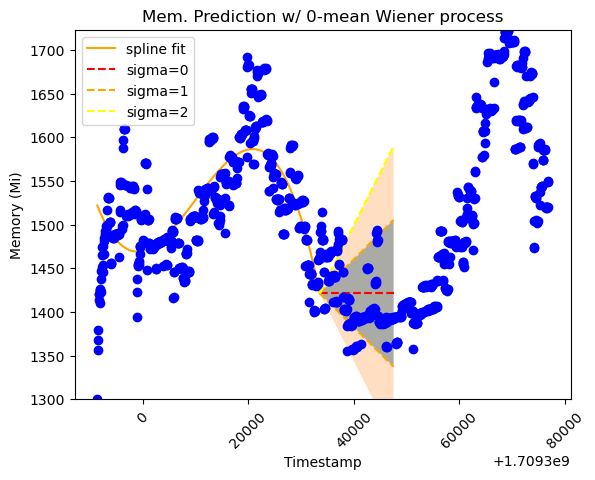

In [78]:
plt.plot(X_train, BSpline(*tck_s)(X_train), '-', label='spline fit', c= 'orange')

xnew = np.arange(max(X_train), max(X_train) + 15000, 1000)
last_x = max(X_train)
last_y = BSpline(*tck_s)(last_x)

sigma = 0.006
y_base = last_y  + 0.0 * xnew
slope = sigma * (xnew - last_x)

plt.plot(xnew, y_base, '--', c="red", label = "sigma=0")
plt.plot(xnew, y_base + slope, '--', c="orange", label = "sigma=1")
plt.plot(xnew, y_base - slope, '--', c="orange")
plt.fill_between(xnew, y_base - slope, y_base + slope, alpha=0.5)
plt.plot(xnew, y_base + 2 * slope, '--', c="yellow", label = "sigma=2")
plt.plot(xnew, y_base + 2 * slope, '--', c="yellow")
plt.fill_between(xnew, y_base - 2 * slope, y_base + 2 * slope, alpha=0.25)

plt.plot(X, Y, 'o', c="b")

ymin = min(node_stats['Memory'])
ymax = max(node_stats['Memory'])
plt.ylim(ymin, ymax)
plt.xticks(rotation=45)  

plt.title("Mem. Prediction w/ 0-mean Wiener process")
plt.xlabel('Timestamp')
plt.ylabel('Memory (Mi)')

plt.legend()
plt.show()

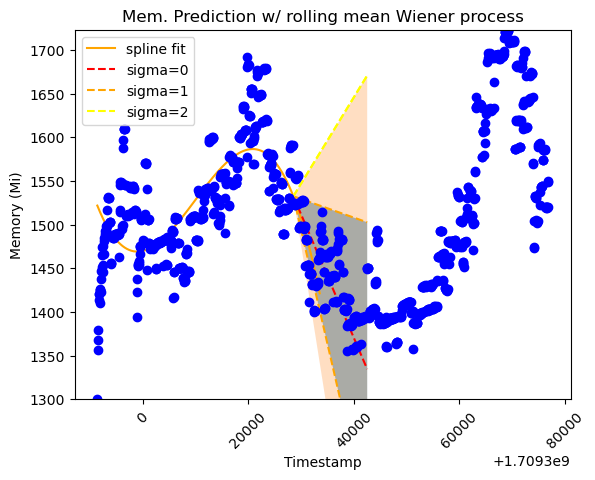

In [88]:
plt.plot(X_train, BSpline(*tck_s)(X_train), '-', label='spline fit', c= 'orange')

xnew = np.arange(max(X_train)-5000, max(X_train) + 10000, 1000)
last_x = max(X_train)-5000
last_y = BSpline(*tck_s)(last_x)
last_m = (BSpline(*tck_s)(last_x) - BSpline(*tck_s)(last_x - 1000))/1000

sigma = 0.012
y_base = last_y  + last_m * (xnew - last_x)
slope = sigma * (xnew - last_x)

plt.plot(xnew, y_base, '--', c="red", label = "sigma=0")
plt.plot(xnew, y_base + slope, '--', c="orange", label = "sigma=1")
plt.plot(xnew, y_base - slope, '--', c="orange")
plt.fill_between(xnew, y_base - slope, y_base + slope, alpha=0.5)
plt.plot(xnew, y_base + 2 * slope, '--', c="yellow", label = "sigma=2")
plt.plot(xnew, y_base + 2 * slope, '--', c="yellow")
plt.fill_between(xnew, y_base - 2 * slope, y_base + 2 * slope, alpha=0.25)

plt.plot(X, Y, 'o', c="b")

ymin = min(node_stats['Memory'])
ymax = max(node_stats['Memory'])
plt.ylim(ymin, ymax)
plt.xticks(rotation=45)  

plt.title("Mem. Prediction w/ rolling mean Wiener process")
plt.xlabel('Timestamp')
plt.ylabel('Memory (Mi)')

plt.legend()
plt.show()

###### plt.figure(figsize=(10, 6))
plt.scatter(node_stats.sort_values(by='Timestamp')['Timestamp'], node_stats['Memory'], marker='o', linestyle='-')
plt.plot(node_stats['Timestamp'], list(map((lambda x : basis(x.timestamp())), node_stats['Timestamp'])), color='r')
plt.title('Memory usage over time')
plt.xlabel('Timestamp')
plt.ylabel('Memory (Mi)')

ymin = min(node_stats['Memory'])
ymax = max(node_stats['Memory'])
plt.ylim(ymin, ymax)
plt.xticks(rotation=45)  
plt.tight_layout()  
plt.show()